## Projeto 1 – Rede Adaline

Classificação de retornos de radares ionosféricos utilizando o dataset Ionosphere.

### 1. Importação das bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### 2. Carregamento e exploração do dataset

In [2]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/"
    "ionosphere/ionosphere.data"
)

colunas = [f"atributo_{i}" for i in range(1, 35)]
colunas.append("classe")

df = pd.read_csv(url, header=None, names=colunas)

df.head()

,atributo_1,atributo_2,atributo_3,atributo_4,atributo_5,atributo_6,atributo_7,atributo_8,atributo_9,atributo_10,...,atributo_26,atributo_27,atributo_28,atributo_29,atributo_30,atributo_31,atributo_32,atributo_33,atributo_34,classe
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,b
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,g


In [3]:
print("Dimensões do dataset:", df.shape)

print("\nInformações do dataset:")
df.info()

print("\nDistribuição das classes:")
print(df["classe"].value_counts())

Dimensões do dataset: (351, 35)

Informações do dataset:
<class 'pandas.DataFrame'>
RangeIndex: 351 entries, 0 to 350
Data columns (total 35 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   atributo_1   351 non-null    int64  
 1   atributo_2   351 non-null    int64  
 2   atributo_3   351 non-null    float64
 3   atributo_4   351 non-null    float64
 4   atributo_5   351 non-null    float64
 5   atributo_6   351 non-null    float64
 6   atributo_7   351 non-null    float64
 7   atributo_8   351 non-null    float64
 8   atributo_9   351 non-null    float64
 9   atributo_10  351 non-null    float64
 10  atributo_11  351 non-null    float64
 11  atributo_12  351 non-null    float64
 12  atributo_13  351 non-null    float64
 13  atributo_14  351 non-null    float64
 14  atributo_15  351 non-null    float64
 15  atributo_16  351 non-null    float64
 16  atributo_17  351 non-null    float64
 17  atributo_18  351 non-null    float64
 18  atri

In [4]:
print("Total de valores ausentes:")
print(df.isnull().sum().sum())

atributos_constantes = [
    coluna
    for coluna in df.columns[:-1]
    if df[coluna].nunique() <= 1
]

print("\nAtributos constantes:")
print(atributos_constantes)

Total de valores ausentes:
0

Atributos constantes:
['atributo_2']


In [5]:
df["classe"] = df["classe"].map({
    "g": 1,
    "b": -1
})

print(df["classe"].value_counts())

classe
 1    225
-1    126
Name: count, dtype: int64


### 3. Pré-processamento dos dados

In [6]:
X = df.drop(columns=["classe"])
y = df["classe"]

print("Dimensão de X:", X.shape)
print("Dimensão de y:", y.shape)

Dimensão de X: (351, 34)
Dimensão de y: (351,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Amostras de treino:", len(X_train))
print("Amostras de teste:", len(X_test))

Amostras de treino: 280
Amostras de teste: 71


In [8]:
colunas_constantes = X_train.columns[
    X_train.nunique() <= 1
].tolist()

X_train = X_train.drop(columns=colunas_constantes)
X_test = X_test.drop(columns=colunas_constantes)

print("Colunas removidas:", colunas_constantes)
print("Atributos restantes:", X_train.shape[1])

Colunas removidas: ['atributo_2']
Atributos restantes: 33


In [9]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

print("Média dos atributos de treino:")
print(np.round(X_train.mean(axis=0), 4))

print("\nDesvio-padrão dos atributos de treino:")
print(np.round(X_train.std(axis=0), 4))

Média dos atributos de treino:
[ 0. -0. -0.  0.  0.  0.  0. -0.  0.  0.  0.  0.  0.  0. -0.  0.  0.  0.
 -0. -0. -0. -0.  0. -0.  0.  0. -0.  0. -0.  0. -0.  0. -0.]

Desvio-padrão dos atributos de treino:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 4. Implementação da rede Adaline

In [10]:
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

### 5. Estudo das taxas de aprendizagem

In [11]:
learning_rates = [0.0001, 0.001, 0.01, 0.05, 0.1]

epochs = 200

models = {}
loss_histories = {}
results = []

for lr in learning_rates:

    model = SGDRegressor(
        loss="squared_error",
        penalty=None,
        learning_rate="constant",
        eta0=lr,
        max_iter=epochs,
        tol=None,
        random_state=42
    )

    losses = []

    for epoch in range(epochs):

        model.partial_fit(X_train, y_train)

        output = model.predict(X_train)

        loss = 0.5 * mean_squared_error(y_train, output)

        losses.append(loss)

    models[lr] = model
    loss_histories[lr] = losses

    results.append({
        "Taxa de aprendizagem": lr,
        "Loss inicial": losses[0],
        "Loss final": losses[-1],
        "Menor loss": min(losses)
    })

In [12]:
results_df = pd.DataFrame(results)

results_df

,Taxa de aprendizagem,Loss inicial,Loss final,Menor loss
0,0.0001,4.615716e-01,1.906735e-01,1.906735e-01
1,0.0010,2.993224e-01,1.861833e-01,1.861833e-01
2,0.0100,2.402466e-01,2.309933e-01,2.309933e-01
3,0.0500,4.953087e+04,2.621080e+23,4.953087e+04
4,0.1000,1.028448e+24,1.635109e+24,7.078259e+23


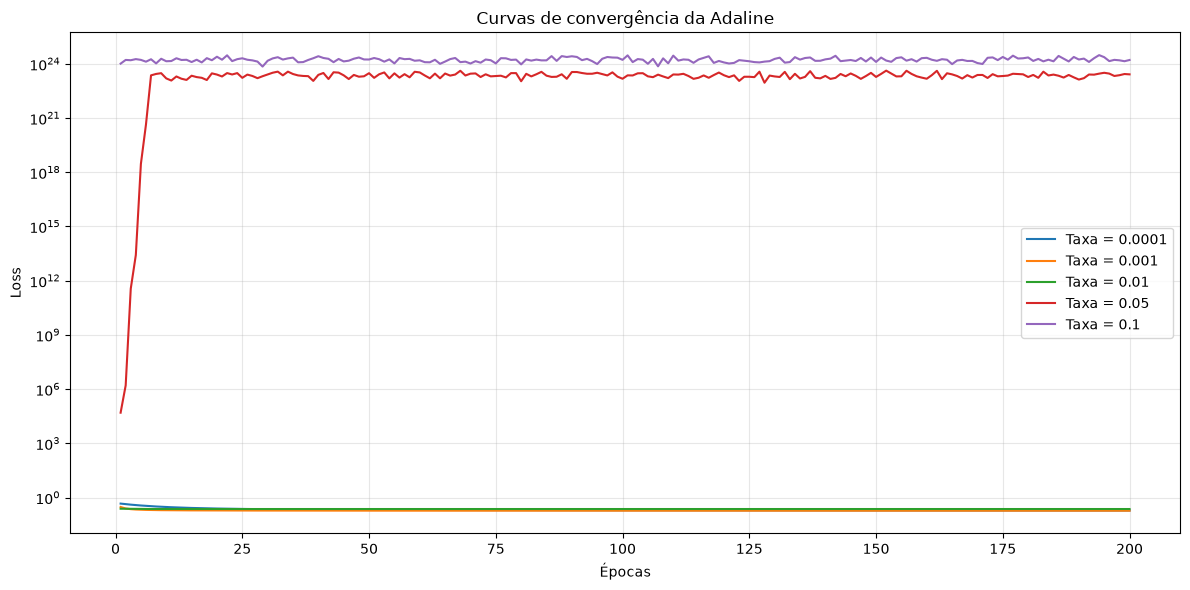

In [13]:
plt.figure(figsize=(12, 6))

for lr, losses in loss_histories.items():

    plt.plot(
        range(1, epochs + 1),
        losses,
        label=f"Taxa = {lr}"
    )

plt.title("Curvas de convergência da Adaline")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

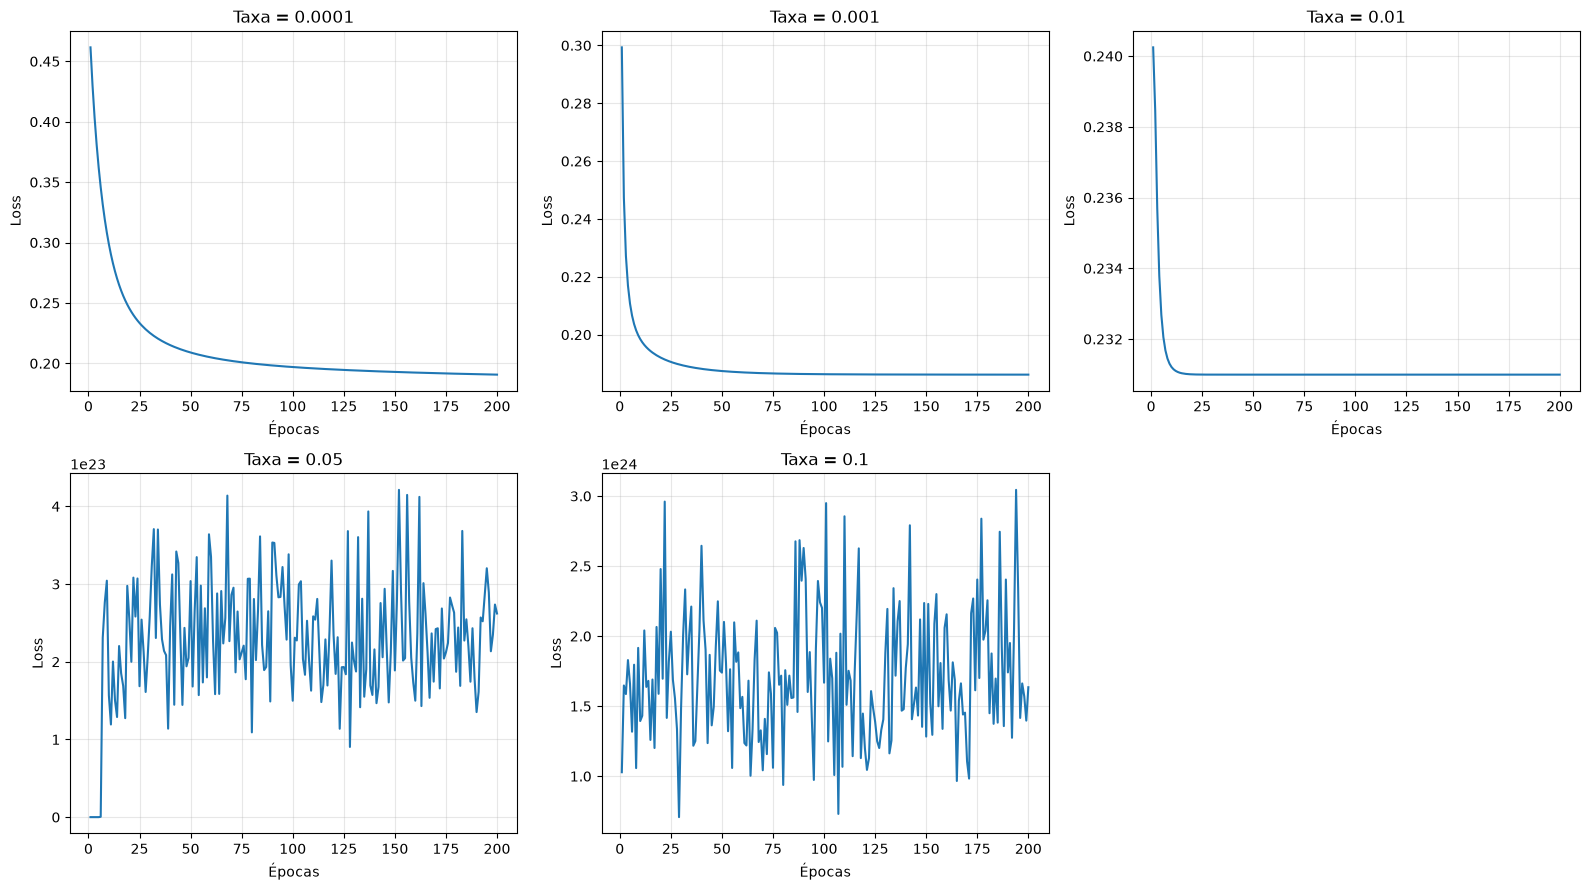

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, (lr, losses) in enumerate(loss_histories.items()):

    axes[i].plot(range(1, epochs + 1), losses)

    axes[i].set_title(f"Taxa = {lr}")
    axes[i].set_xlabel("Épocas")
    axes[i].set_ylabel("Loss")
    axes[i].grid(alpha=0.3)

axes[5].axis("off")

plt.tight_layout()
plt.show()

In [15]:
best_lr = min(
    learning_rates,
    key=lambda lr: loss_histories[lr][-1]
)

best_model = models[best_lr]

print("Melhor taxa de aprendizagem:", best_lr)
print("Loss final:", loss_histories[best_lr][-1])

Melhor taxa de aprendizagem: 0.001
Loss final: 0.18618326688469372


### 6. Avaliação do modelo no conjunto de teste

In [16]:
output = best_model.predict(X_test)

y_pred = np.where(output >= 0, 1, -1)

print("Primeiras 10 previsões:")
print(y_pred[:10])

print("\nPrimeiros 10 valores reais:")
print(y_test[:10])

Primeiras 10 previsões:
[ 1  1  1  1  1  1  1 -1  1  1]

Primeiros 10 valores reais:
[ 1  1  1  1  1  1  1 -1  1  1]


#### 6.1. Métricas de avaliação

In [20]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, pos_label=1)

recall = recall_score(y_test, y_pred, pos_label=1)

f1 = f1_score(y_test, y_pred, pos_label=1)

print(f"Acurácia: {accuracy:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Acurácia: 0.9296
Precisão: 0.9020
Recall: 1.0000
F1-score: 0.9485


#### 6.2. Relatório de classificação por classe

In [21]:
print(classification_report(
    y_test,
    y_pred,
    labels=[-1, 1],
    target_names=["Bad", "Good"],
    digits=4
))

              precision    recall  f1-score   support

         Bad     1.0000    0.8000    0.8889        25
        Good     0.9020    1.0000    0.9485        46

    accuracy                         0.9296        71
   macro avg     0.9510    0.9000    0.9187        71
weighted avg     0.9365    0.9296    0.9275        71



#### 6.3. Matriz de confusão 

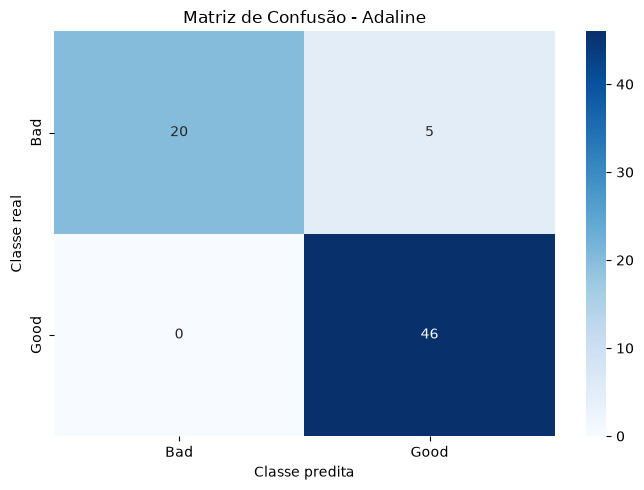

In [18]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[-1, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Bad", "Good"],
    yticklabels=["Bad", "Good"]
)

plt.title("Matriz de Confusão - Adaline")
plt.xlabel("Classe predita")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()